## Convolutional Neural Networks (CNN)

Convolutional Neural Network(CNN) is a subclass of an artificial neural network(ANN) which is mostly used for image-related applications. The input for a CNN is an image, and there are different operations performed on that image to extract its important features of it and then decide the weights to give the correct output. These features are learned using filters. Filters help to detect certain image properties such as horizontal lines, vertical lines, edges, corners, etc. As we go deep into the network, the network learns to defect complex features such as objects, face, background, foreground, etc

## CNN Model Architechture:

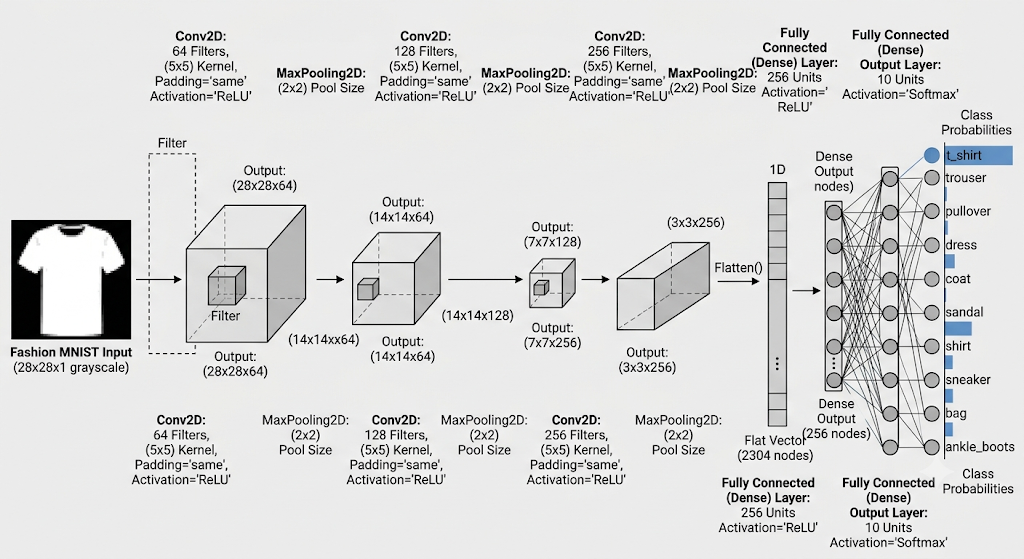

In [1]:
# To load the mnist data
from keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
# importing various types of hidden layers
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten
# Adam optimizer for better LR and less loss
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import numpy as np

In [2]:
import keras
import tensorflow as tf
print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)

Keras: 3.15.1
TensorFlow: 2.21.0


In [3]:
# Split the data into training and testing
(trainX, trainy), (testX, testy) = fashion_mnist.load_data()
# Print the dimensions of the dataset
print('Train: X = ', trainX.shape)
print('Test: X = ', testX.shape)

Train: X =  (60000, 28, 28)
Test: X =  (10000, 28, 28)


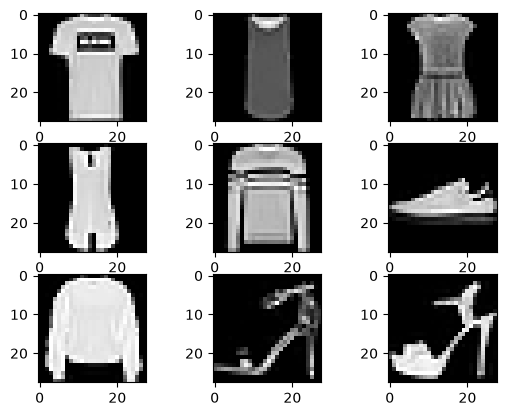

In [4]:
for i in range(1, 10):
    # Create a 3x3 grid and place the
    # image in ith position of grid
    plt.subplot(3, 3, i)
    # Insert ith image with the color map 'grap'
    plt.imshow(trainX[i], cmap=plt.get_cmap('gray'))

# Display the entire plot
plt.show()

### Data Analysis
In the data analysis, we will see the number of images available, the dimensions of each image, etc. We will then split the data into training and testing.

The fashion MNIST dataset consists of 60,000 images for the training set and 10,000 images for the testing set. Each image is a 28 x 28 size grayscale image categorized into ten different classes.

Each image has a label associated with it. There are, in total, ten labels available, and they are:

- T-shirt/top
- Trouser
- Pullover
- Dress
- Coat
- Sandal
- Shirt
- Sneaker
- Bag
- Ankle boot

In [5]:
trainX = np.expand_dims(trainX, -1)
testX = np.expand_dims(testX, -1)

print(trainX.shape)

(60000, 28, 28, 1)


## CNNs have three main types of layers:

- **Convolutional Layer:** This layer is the main layer of CNN. When an image is fed into the convolution layer, a filter or a kernel of varying size but generally of size 3x3 is used to detect the features. The dot product is carried out with the image, and the kernel is the output is stored in a cell of a matrix which is called a feature map or an activation map. Once the operation is done, the filter moves by a distance and then repeats the process. This distance is called a stride. After each convolution operation, a ReLu transformation is applied to the feature map to introduce non-linearity into the model.

- **Pooling Layer:** This layer is responsible for reducing the number of parameters in the next layer. It is also known as downsampling or dimensionality reduction.

- **Fully Connected Layer:** Neurons in this layer have full connectivity to all the neurons in the preceding layer and the succeeding layer. FC layer helps to map the input with the output.


## Model Training

We will create a straightforward CNN architecture with three convolutional layers followed by three max-pooling layers for this dataset. Convolutional layers will perform the convolutional operation and extract the features, while the max-pooling layer will downsample the features.

In [6]:
def model_arch():
    models = Sequential()
    # We are learning 64 
    # filters with a kernel size of 5x5
    models.add(Conv2D(64, (5, 5),
                      padding="same",
                      activation="relu", 
                      input_shape=(28, 28, 1)))
    
    # Max pooling will reduce the
    # size with a kernel size of 2x2
    models.add(MaxPooling2D(pool_size=(2, 2)))
    models.add(Conv2D(128, (5, 5), padding="same",
                      activation="relu"))
    
    models.add(MaxPooling2D(pool_size=(2, 2)))
    models.add(Conv2D(256, (5, 5), padding="same", 
                      activation="relu"))
    
    models.add(MaxPooling2D(pool_size=(2, 2)))
    
    # Once the convolutional and pooling 
    # operations are done the layer
    # is flattened and fully connected layers
    # are added
    models.add(Flatten())
    models.add(Dense(256, activation="relu"))
    
    # Finally as there are total 10
    # classes to be added a FCC layer of
    # 10 is created with a softmax activation
    # function
    models.add(Dense(10, activation="softmax"))
    return models

# Model Compilation

In [19]:
model = model_arch()

# METRICS = ['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
# model.compile(loss='categorical_crossentropy', optimizer=Adam(learning_rate=1e-3), metrics=METRICS)

model.compile(optimizer=Adam(learning_rate=1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_accuracy'])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)                    │ (None, 28, 28, 64)          │           1,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 14, 14, 128)         │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 7, 7, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 7, 7, 256)           │         819,456 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 3, 3, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 256)                 │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,618,698 (6.17 MB)

 Trainable params: 1,618,698 (6.17 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
history = model.fit(
    trainX.astype(np.float32), trainy.astype(np.float32),
    epochs=10,
    steps_per_epoch=100,
    validation_split=0.33
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 51s 503ms/step - loss: 4.0571 - sparse_categorical_accuracy: 0.6384 - val_loss: 0.4342 - val_sparse_categorical_accuracy: 0.8425
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 55s 552ms/step - loss: 0.3838 - sparse_categorical_accuracy: 0.8594 - val_loss: 0.3686 - val_sparse_categorical_accuracy: 0.8652
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 56s 557ms/step - loss: 0.3200 - sparse_categorical_accuracy: 0.8835 - val_loss: 0.3223 - val_sparse_categorical_accuracy: 0.8797
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 57s 569ms/step - loss: 0.2757 - sparse_categorical_accuracy: 0.8987 - val_loss: 0.3017 - val_sparse_categorical_accuracy: 0.8907
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 58s 578ms/step - loss: 0.2586 - sparse_categorical_accuracy: 0.9043 - val_loss: 0.3038 - val_sparse_categorical_accuracy: 0.8907
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 57s 573ms/step - loss: 0.2276 - sparse_categorical_accuracy: 0.9154 - val_loss: 0.3085 - val_sparse_categorical_acc

In [27]:
model.save_weights('cnn_mnist_model.weights.h5', overwrite=True)

## Model Analysis

In this section, we will plot some graphs related to accuracy and loss to evaluate model performance.
First, we will see the accuracy and plot the loss.

In [28]:
# Save only weights
reff_model=model.load_weights('cnn_mnist_model.weights.h5')

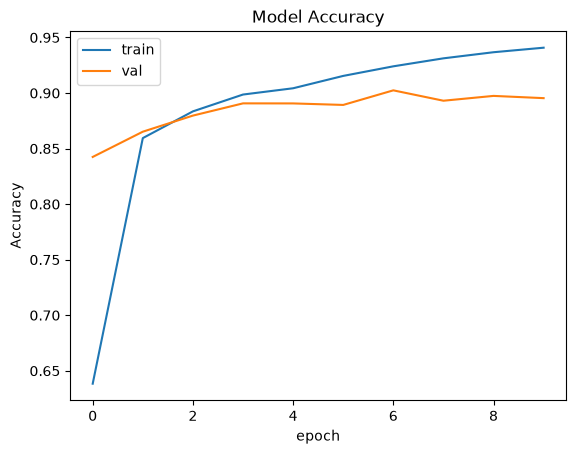

In [23]:
# Accuracy vs Epoch plot
plt.plot(history.history['sparse_categorical_accuracy'])
plt.plot(history.history['val_sparse_categorical_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

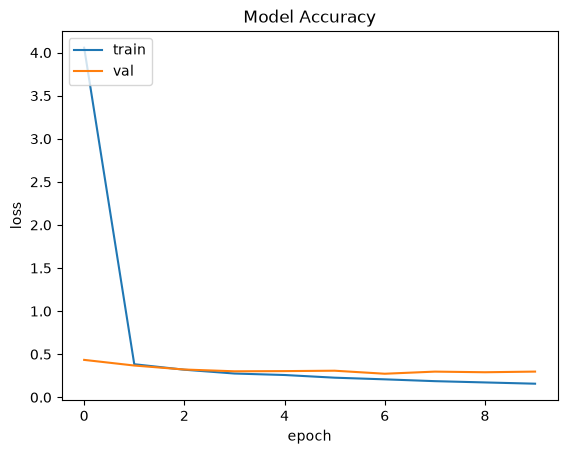

In [24]:
# Loss vs Epoch plot
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Accuracy')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
ankle_boots


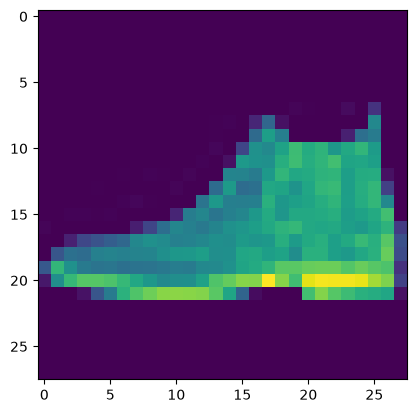

In [34]:
# There are 10 output labels for the Fashion MNIST dataset
labels = ['t_shirt', 'trouser', 'pullover', 'dress', 'coat',
          'sandal', 'shirt', 'sneaker', 'bag', 'ankle_boots']
# Make a prediction
predictions = model.predict(testX[:1])
label = labels[np.argmax(predictions)]

print(label)
plt.imshow(testX[:1][0])
plt.show()